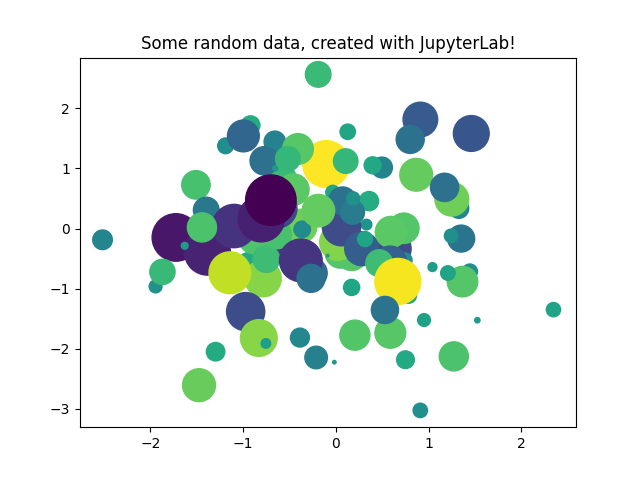

In [1]:
from matplotlib import pyplot as plt
import numpy as np

# Generate 100 random data points along 3 dimensions
x, y, scale = np.random.randn(3, 100)
fig, ax = plt.subplots()

# Map each onto a scatterplot we'll create with Matplotlib
ax.scatter(x=x, y=y, c=scale, s=np.abs(scale)*500)
ax.set(title="Some random data, created with JupyterLab!")
plt.show()

age       15
gender    53
city       0
salary    12
score      0
dtype: int64
              age        salary     score
count  200.000000    200.000000  200.0000
mean    36.655000  54506.340000   69.6750
std     11.178586  19399.329068   17.4638
min     18.000000  20052.000000   40.0000
25%     28.000000  38135.000000   54.0000
50%     36.000000  53705.000000   71.0000
75%     44.250000  71516.250000   85.0000
max     59.000000  88988.000000   99.0000
city
Bangalore    51847.195122
Delhi        55046.916667
Mumbai       58318.045455
Pune         52849.527273
Name: salary, dtype: float64


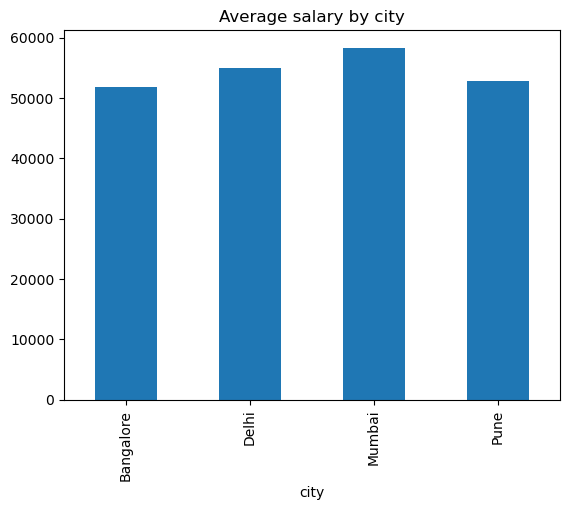

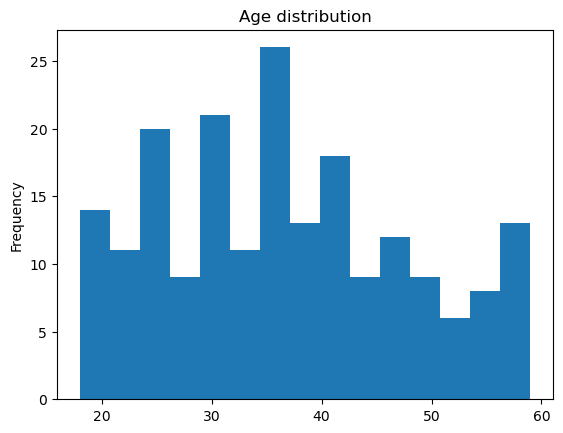

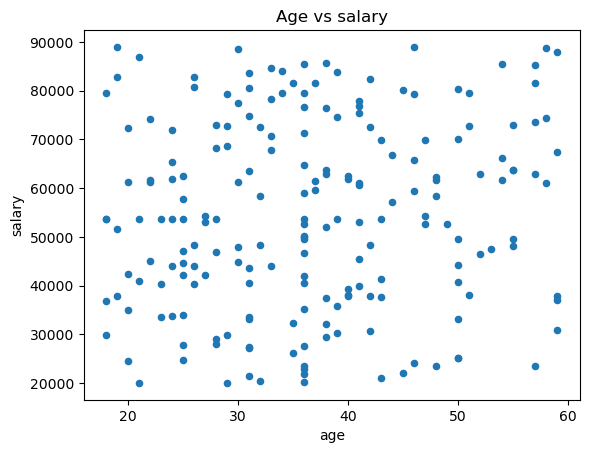

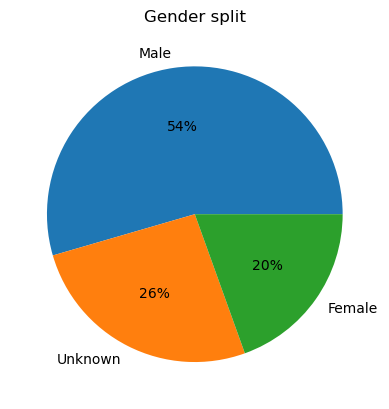

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Create a raw (messy) dataset
np.random.seed(1)
n = 200
df = pd.DataFrame({
    "age": np.random.randint(18, 60, n).astype(float),
    "gender": np.random.choice(["Male", "Female", " male", None], n),
    "city": np.random.choice(["Delhi", "Mumbai", "Pune", "Bangalore"], n),
    "salary": np.random.randint(20000, 90000, n).astype(float),
    "score": np.random.randint(40, 100, n).astype(float),
})
df.loc[np.random.choice(n, 15), "age"] = np.nan
df.loc[np.random.choice(n, 10), "salary"] = np.nan
df = pd.concat([df, df.head(10)])  # duplicates

# CLEAN
print(df.isnull().sum())
df = df.drop_duplicates()
df["age"] = df["age"].fillna(df["age"].median())
df["salary"] = df["salary"].fillna(df["salary"].median())
df["gender"] = df["gender"].str.strip().str.title().fillna("Unknown")

# PROCESS
print(df.describe())
print(df.groupby("city")["salary"].mean())

# VISUALIZE
df.groupby("city")["salary"].mean().plot(kind="bar", title="Average salary by city")
plt.show()

df["age"].plot(kind="hist", bins=15, title="Age distribution")
plt.show()

df.plot(kind="scatter", x="age", y="salary", title="Age vs salary")
plt.show()

df["gender"].value_counts().plot(kind="pie", autopct="%1.0f%%", title="Gender split")
plt.show()